# Cluster-based train/test split

MMseqs2 clustering at **30% identity, 80% bidirectional coverage**.

Rule: every cluster goes **wholly** to train or to test, so no test sequence has a
homologue above 30% identity in the training set.

Balance: each class has a fixed test quota of 20%; a cluster enters the test set
only if it fits the remaining quota of **every** class it contains.

Apply Coverage and Identity Diferent Threshold <br>
Identity:30%    Coverage: 80%<br>
Identity:40%    Coverage: 80%<br>
Identity:50%    Coverage: 80%<br>

In [3]:
import pandas as pd

thresholds = {
    30: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30_80_per/cluster_result_30.tsv',
    40: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/40_80_per/cluster_result_40.tsv',
    50: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/50_80_per/cluster_result_50.tsv'
}

for thresh, path in thresholds.items():
    df = pd.read_csv(path, sep='\t', header=None, names=['representative', 'member'])
    n_clusters = df['representative'].nunique()
    n_sequences = len(df)
    avg_cluster_size = n_sequences / n_clusters
    print(f"Threshold {thresh}%: {n_clusters} clusters, {n_sequences} sequences, avg cluster size {avg_cluster_size:.2f}")

Threshold 30%: 3275 clusters, 3711 sequences, avg cluster size 1.13
Threshold 40%: 3407 clusters, 3711 sequences, avg cluster size 1.09
Threshold 50%: 3537 clusters, 3711 sequences, avg cluster size 1.05


                     30         40         50
class                                        
Non-secreted   2.512255   1.102941   0.551471
Sec           21.171171  15.315315   7.432432
T1SS          20.979021  16.083916  10.489510
T2SS          11.538462  10.256410   2.564103
T3SS          15.955056  12.134831   7.415730
T4SS           3.467153   2.554745   1.277372
T5SS          28.205128  25.641026  17.948718
T6SS          30.769231  16.117216   8.791209
Tat           47.706422  40.366972  22.935780


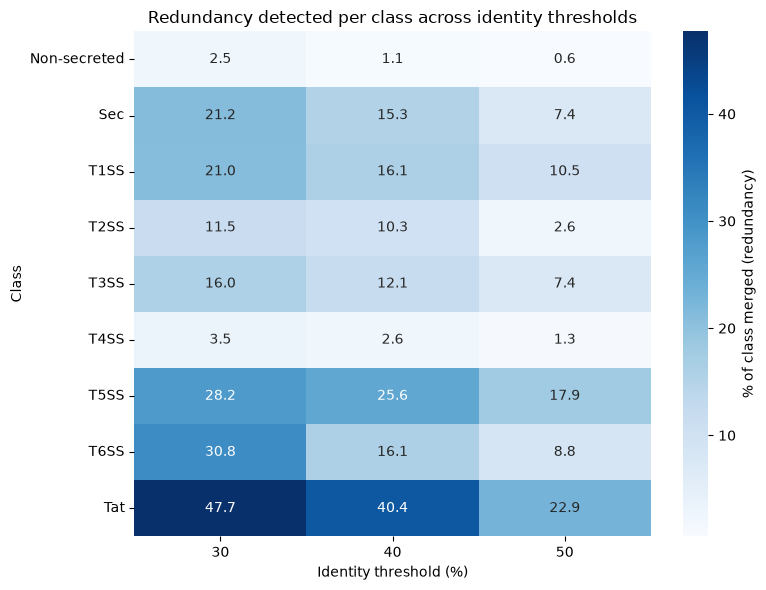

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def get_class(seq_id):
    return seq_id.rsplit('-', 1)[0]

thresholds = {
    30: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30_80_per/cluster_result_30.tsv',
    40: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/40_80_per/cluster_result_40.tsv',
    50: 'C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss/Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/50_80_per/cluster_result_50.tsv'
}


class_redundancy = {}

for thresh, path in thresholds.items():
    df = pd.read_csv(path, sep='\t', header=None, names=['representative', 'member'])
    df['class'] = df['member'].apply(get_class)
    
    # total sequences per class
    total_per_class = df.groupby('class').size()
    # unique clusters per class (representative count, per class)
    unique_clusters_per_class = df.groupby('class')['representative'].nunique()
    
    merged = total_per_class - unique_clusters_per_class
    pct_merged = (merged / total_per_class) * 100
    class_redundancy[thresh] = pct_merged

heatmap_df = pd.DataFrame(class_redundancy)
print(heatmap_df)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_df, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of class merged (redundancy)'})
plt.title('Redundancy detected per class across identity thresholds')
plt.xlabel('Identity threshold (%)')
plt.ylabel('Class')
plt.tight_layout()
plt.savefig('threshold_comparison_heatmap.png', dpi=150)
plt.show()

# Import path and file/folder

In [10]:
import pandas as pd
from collections import Counter
from pathlib import Path

BASE  = Path("C:/Users/sumit/OneDrive/Documenten/Thesis/comp-ss")
TSV   = BASE / "Results/sumit_secretion_prediction/phase0_dataset_prep/MMsques2/Re-configure/30_80_per/cluster_result_30.tsv"
FASTA = BASE / "Results/sumit_secretion_prediction/phase0_dataset_prep/Clean_Data/combine_final.fasta"
OUT   = BASE / "Results/sumit_secretion_prediction/phase0_dataset_prep/Train_Test"
OUT.mkdir(parents=True, exist_ok=True)

TEST_FRACTION = 0.20

print("TSV  exists:", TSV.exists())
print("FASTA exists:", FASTA.exists())

TSV  exists: True
FASTA exists: True


# Load .tsv file wehre two column Representative (Cluster_id) and member (Protein_id)

1. Apply Transformation One row per Protein_id  and add label column from protein_id

In [11]:
tsv = pd.read_csv(TSV, sep='\t', header=None, names=['representative', 'member'])
tsv['label'] = tsv['member'].str.rsplit('-', n=1).str[0]

print("rows (sequences):", len(tsv))
print("clusters:", tsv['representative'].nunique())
tsv.head()

rows (sequences): 3711
clusters: 3275


,representative,member,label
0,T2SS-14,T2SS-14,T2SS
1,T2SS-46,T2SS-46,T2SS
2,T2SS-46,T2SS-36,T2SS
3,T3SS-32,T3SS-32,T3SS
4,T3SS-64,T3SS-64,T3SS


2. Create new .csv file where three column Label, Cluster_id, Protein_id  and sort by cluster and label

In [12]:
cluster_id_map, class_counters = {}, {}
for rep in tsv['representative'].unique():
    cls = tsv.loc[tsv.representative == rep, 'label'].iloc[0]
    class_counters[cls] = class_counters.get(cls, 0) + 1
    cluster_id_map[rep] = f"{cls}_{class_counters[cls]}"

tsv['cluster_id'] = tsv['representative'].map(cluster_id_map)

seq_df = (tsv[['label', 'cluster_id', 'member']]
            .rename(columns={'member': 'Protein_id'})
            .sort_values(['label', 'cluster_id'])
            .reset_index(drop=True))
seq_df.to_csv(OUT / 'seq_cluster_class_final.csv', index=False, sep=';')

print("per-protein rows:", len(seq_df))
seq_df.head(10)

per-protein rows: 3711


,label,cluster_id,Protein_id
0,Non-secreted,Non-secreted_1,Non-secreted-7
1,Non-secreted,Non-secreted_10,Non-secreted-295
2,Non-secreted,Non-secreted_100,Non-secreted-1329
3,Non-secreted,Non-secreted_1000,Non-secreted-1115
4,Non-secreted,Non-secreted_1001,Non-secreted-1148
5,Non-secreted,Non-secreted_1002,Non-secreted-1180
6,Non-secreted,Non-secreted_1003,Non-secreted-1212
7,Non-secreted,Non-secreted_1004,Non-secreted-1244
8,Non-secreted,Non-secreted_1005,Non-secreted-1276
9,Non-secreted,Non-secreted_1006,Non-secreted-1308


3. Fix the threshold of Test and Train here Train appro. 80% and Test appro. 20% Try to reach of each class via clustering split.

    First for Split test-set because we have total 3711 Protein seq. which is spread across 3275 cluster .<br>
    total 3711 Sequence<br>
    total Cluster 3275 <br>
    Singleton cluster 3008<br>
    Multi member cluster 267<br>

    Here First we fill test-set using singleton cluster across all 9-class , Once reach each class Appro. 20% then Rest of the Cluster goes to Train-set <br>

    | Secretion System | Total | Train | Test |
    | :--- | :--- | :--- | :--- |
    | **Sec Pathways** | 444 | 355 | 89 |
    | **Tat Pathways** | 109 | 87 | 22 |
    | **T1SS** | 143 | 114 | 29 |
    | **T2SS** | 78 | 62 | 16 |
    | **T3SS** | 445 | 356 | 89 |
    | **T4SS** | 558 | 438 | 110 |
    | **T5SS** | 39 | 31 | 8 |
    | **T6SS** | 273 | 218 | 55 |
    | **Non-Secreted** | 1,632 | 1,306 | 326 |
    | **Total** | **3,721** | **2,967** | **754** |

In [13]:
#Counts the total number of protein sequences available for each class
total  = Counter(seq_df['label'])

#Calculates the exact number of sequences that must go into the test set for each class.
target = {c: round(n * TEST_FRACTION) for c, n in total.items()}

#New DF where two column total seqeunce of each class and how much goes to test-set
quota = pd.DataFrame({'total': pd.Series(total), 'test_quota': pd.Series(target)})

# Add new column rest of goes to train
quota['train_expected'] = quota['total'] - quota['test_quota']

#Preview Decending order large class preview first (Non-Secreted)
quota.sort_values('total', ascending=False)

,total,test_quota,train_expected
Non-secreted,1632,326,1306
T4SS,548,110,438
T3SS,445,89,356
Sec,444,89,355
T6SS,273,55,218
T1SS,143,29,114
Tat,109,22,87
T2SS,78,16,62
T5SS,39,8,31


Cluster content and counted by each class<br>
each cluster how many Protein sequence of each class hold and 

In [14]:
# Group data by cluster_id
grouped = seq_df.groupby('cluster_id')

# Count class labels inside each cluster
clusters = {}
for cluster_id, group in grouped:
    # Count how many of each label are in this specific cluster
    label_counts = Counter(group['label'])
    clusters[cluster_id] = label_counts

# Calculate total sequences in each cluster
sizes = {}
for cluster_id, label_counts in clusters.items():
    # Sum up all the counts for this cluster
    total_sequences = sum(label_counts.values())
    sizes[cluster_id] = total_sequences

assert sum(sizes.values()) == len(seq_df), "sequence count changed"

mixed = [c for c in clusters if len(clusters[c]) > 1]
print("clusters:      ", len(clusters))
print("singletons:    ", sum(1 for c in sizes if sizes[c] == 1))
print("multi-member:  ", sum(1 for c in sizes if sizes[c] > 1))
print("mixed-class:   ", len(mixed))
print()
for c in mixed[:5]:
    print(f"  {c:16s} size={sizes[c]:2d}  {dict(clusters[c])}")

clusters:       3275
singletons:     3008
multi-member:   267
mixed-class:    25

  Sec_107          size= 7  {'Sec': 1, 'Tat': 6}
  Sec_11           size= 4  {'Sec': 2, 'T2SS': 2}
  Sec_158          size= 2  {'Sec': 1, 'T5SS': 1}
  Sec_164          size= 2  {'Sec': 1, 'T2SS': 1}
  Sec_174          size= 4  {'Sec': 3, 'T6SS': 1}


In [ ]:
# Sort clusters by size (smallest first) to keep the sorting predictable/deterministic
def get_cluster_size(cid):
    return (sizes[cid], cid)

order = sorted(clusters, key=get_cluster_size)


# Assign each cluster to 'test' or 'train' based on target quotas
test_count = Counter()
assign = {}

for cid in order:
    need = clusters[cid]  # Dictionary of label counts for this cluster
    
    # Check if adding this cluster exceeds the target limit for ANY label
    can_fit_in_test = True
    for label, count in need.items():
        if test_count[label] + count > target[label]:
            can_fit_in_test = False
            break  # Stop checking as soon as one label exceeds target limit
    
    # Place cluster in 'test' if it fits, otherwise place in 'train'
    if can_fit_in_test:
        assign[cid] = 'test'
        test_count.update(need)  # Add sequences from this cluster to test_count
    else:
        assign[cid] = 'train'


# Map cluster split back to every sequence in the dataframe
seq_df['final_split'] = seq_df['cluster_id'].map(assign)


# 4. Count and print total test and train clusters
test_clusters_count = 0
train_clusters_count = 0

for split_type in assign.values():
    if split_type == 'test':
        test_clusters_count += 1
    elif split_type == 'train':
        train_clusters_count += 1

print("test clusters: ", test_clusters_count)
print("train clusters:", train_clusters_count)

test clusters:  744
train clusters: 2531


Now Attached each Cluster sequence with Original Protein sequence based on Protein_id <br>
Combine_final.fasta file where all 9-class protein sequence combine

In [16]:
def load_fasta(path):
    seqs, sid, buf = {}, None, []
    for line in open(path):
        line = line.strip()
        if line.startswith('>'):
            if sid: seqs[sid] = ''.join(buf)
            sid, buf = line[1:], []
        else:
            buf.append(line)
    if sid: seqs[sid] = ''.join(buf)
    return seqs

seq_df['Sequence'] = seq_df['Protein_id'].map(load_fasta(FASTA))
print("sequences attached:", seq_df['Sequence'].notna().sum(), "/", len(seq_df))

sequences attached: 3711 / 3711


In [21]:
assert seq_df['final_split'].notna().all(),  "a protein got no split"
assert seq_df['Sequence'].notna().all(),     "a protein is missing from the FASTA"
assert seq_df.groupby('cluster_id')['final_split'].nunique().max() == 1, \
       "a cluster was split across train and test"

for c, n in Counter(seq_df.loc[seq_df.final_split == 'test', 'label']).items():
    assert n <= target[c], f"{c} over quota: {n} > {target[c]}"

train_ids = set(seq_df.loc[seq_df.final_split == 'train', 'Protein_id'])
test_ids  = set(seq_df.loc[seq_df.final_split == 'test',  'Protein_id'])
assert not (train_ids & test_ids), "a protein is in both splits"

seq_df.to_csv(OUT  / 'Final_Split.csv',  index=False, sep=';')
print("all checks passed")

all checks passed


Final Split Train / Test into .csv file  and .fasta file

In [22]:
out = (seq_df[['Protein_id', 'cluster_id', 'label', 'final_split', 'Sequence']]
         .rename(columns={'cluster_id': 'Cluster_id'}))

train = out[out.final_split == 'train'].reset_index(drop=True)
test  = out[out.final_split == 'test'].reset_index(drop=True)

train.to_csv(OUT / 'train.csv', index=False, sep=';')
test.to_csv(OUT  / 'test.csv',  index=False, sep=';')

pd.DataFrame({'cluster_id':   list(assign),
              'cluster_size': [sizes[c] for c in assign],
              'n_classes':    [len(clusters[c]) for c in assign],
              'split':        [assign[c] for c in assign]}) \
  .to_csv(OUT / 'cluster_split_assignment.csv', index=False, sep=';')

for name, d in (('train.fasta', train), ('test.fasta', test)):
    with open(OUT / name, 'w') as f:
        for _, r in d.iterrows():
            f.write(f">{r['Protein_id']}\n{r['Sequence']}\n")
    print(f"wrote {name}: {len(d)} sequences")

wrote train.fasta: 2967 sequences
wrote test.fasta: 744 sequences
